# SafeSight · Notebook C — fine-tune on **Construction Site Safety**

Learns: **person, helmet, vest, mask**. Kaggle input `snehilsanyal/construction-site-safety-image-dataset-roboflow` (~2,800 images, CC BY 4.0).

1. **Data** – load the dataset, map class names to the app's names, remove duplicate images, 70/15/15 split.
2. **Baseline** – the pretrained models the app uses today, on this test set.
3. **Fine-tune** – YOLO (COCO-pretrained) on this dataset.
4. **Evaluate** – mAP@0.5 / mAP@0.5:0.95 per class, confusion matrix, failure gallery.
5. **Cross-dataset test** – the same model on the *other two* datasets (shared classes only).
6. **Export** – ONNX for the app (+ parity and CPU speed check) and per-worker helmet/vest accuracy.

### Kaggle setup
* **Settings → Accelerator: GPU T4 ×2 or P100** · **Internet: On**
* **Add Input → Datasets** (all three notebooks use the same inputs, for the cross-dataset test):
  `andrewmvd/hard-hat-detection` and `snehilsanyal/construction-site-safety-image-dataset-roboflow`
  (Construction-PPE downloads itself).
* Optional: the app's `backend/ppe_core` folder as a Kaggle dataset → enables the per-worker check.

Output: `safesight_css_<model>.onnx` → app → **Models → Register** → **Add to ensemble**.

In [1]:
# ---------------- configuration ----------------
import os, sys, json, random, shutil, time, zipfile, urllib.request
from pathlib import Path

DATASET = "css"                 # this notebook's training data
CLASSES = ['person', 'helmet', 'vest', 'mask']
MODEL = "yolo11s.pt"           # yolo11n.pt / yolo11s.pt / yolo26n.pt / yolo26s.pt (n/s keep the ONNX < 50 MB)
EPOCHS = 60
IMGSZ = 640
BATCH = 16
SEED = 42
CROSS_TEST_MAX = 600            # images per other dataset used for the cross-dataset test

ON_KAGGLE = Path("/kaggle").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path(os.environ.get("WORK_DIR", "work"))
INPUT = Path("/kaggle/input") if ON_KAGGLE else Path(os.environ.get("INPUT_DIR", "inputs"))
RAW, DATA, RES = WORK / "raw", WORK / "data", WORK / "results"
for d in (RAW, DATA, RES):
    d.mkdir(parents=True, exist_ok=True)
CID = {c: i for i, c in enumerate(CLASSES)}
random.seed(SEED)
print("training on", DATASET, "->", CLASSES)

training on css -> ['person', 'helmet', 'vest', 'mask']


In [2]:
!pip -q install -U ultralytics imagehash onnx onnxslim onnxruntime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.8/245.8 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 79.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
google-cloud-aiplatform 2.3.0 requires protobuf!=4.21.0,!=4.21.1,!=4.2

In [3]:
import numpy as np, pandas as pd, yaml, torch, torchvision, imagehash
import matplotlib.pyplot as plt, matplotlib.patches as patches
import xml.etree.ElementTree as ET
from PIL import Image
from ultralytics import YOLO
try:
    from IPython.display import display
except ImportError:
    display = print
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
torch 2.11.0+cu128 | GPU: Tesla T4


## 1 · Data

In [4]:
def download(url, dest):
    dest = Path(dest)
    if not dest.exists():
        print("downloading", url)
        urllib.request.urlretrieve(url, dest)
    return dest

def first(pattern):
    hits = sorted(INPUT.glob(pattern)) if INPUT.exists() else []
    return hits[0] if hits else None

# dataset name -> the app's class names (anything else, e.g. "NO-Hardhat", is dropped)
NAME_MAP = {"helmet": "helmet", "hardhat": "helmet", "vest": "vest", "safety vest": "vest", "gloves": "gloves",
            "boots": "boots", "goggles": "goggles", "mask": "mask", "person": "person", "head": "head"}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def read_yolo(img_dir, lbl_dir, names):
    cmap = {int(k): NAME_MAP.get(str(v).strip().lower()) for k, v in names.items()}
    recs = []
    for ip in sorted(p for p in Path(img_dir).rglob("*") if p.suffix.lower() in IMG_EXT):
        try:
            w, h = Image.open(ip).size
        except Exception:
            continue
        lp = Path(lbl_dir) / ip.relative_to(img_dir).with_suffix(".txt")
        boxes = []
        if lp.exists():
            for line in lp.read_text(encoding="utf-8").splitlines():
                p = line.split()
                if len(p) < 5 or cmap.get(int(float(p[0]))) is None:
                    continue
                v = list(map(float, p[1:]))
                if len(v) == 4:
                    x1, y1, x2, y2 = v[0] - v[2] / 2, v[1] - v[3] / 2, v[0] + v[2] / 2, v[1] + v[3] / 2
                else:  # polygon -> bounding box
                    x1, y1, x2, y2 = min(v[0::2]), min(v[1::2]), max(v[0::2]), max(v[1::2])
                boxes.append((cmap[int(float(p[0]))], x1 * w, y1 * h, x2 * w, y2 * h))
        recs.append(dict(image=ip, w=w, h=h, boxes=boxes))
    return recs

def load_cppe():
    root = Path(os.environ.get("CPPE_DIR", RAW / "construction-ppe"))
    if not (root / "images").exists():
        z = download("https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip", RAW / "construction-ppe.zip")
        with zipfile.ZipFile(z) as f:
            f.extractall(root)
    names = yaml.safe_load(open(root / "data.yaml", encoding="utf-8"))["names"]
    return read_yolo(root / "images", root / "labels", names), {"person", "helmet", "vest", "gloves", "boots", "goggles"}

def load_css():
    root = first("**/css-data")
    if root is None:
        return None, set()
    yml = next(iter(sorted(root.rglob("data.yaml"))), None)
    names = yaml.safe_load(open(yml, encoding="utf-8"))["names"] if yml else ["Hardhat", "Mask", "NO-Hardhat",
        "NO-Mask", "NO-Safety Vest", "Person", "Safety Cone", "Safety Vest", "machinery", "vehicle"]
    names = dict(enumerate(names)) if isinstance(names, list) else names
    recs = []
    for s in ("train", "valid", "test"):
        if (root / s / "images").exists():
            recs += read_yolo(root / s / "images", root / s / "labels", names)
    return recs, {"person", "helmet", "vest", "mask"}

def load_hardhat():
    ann = first("**/annotations/*.xml")
    if ann is None:
        return None, set()
    root = ann.parent.parent
    recs = []
    for xp in sorted((root / "annotations").glob("*.xml")):
        cand = list((root / "images").glob(xp.stem + ".*"))
        if not cand:
            continue
        w, h = Image.open(cand[0]).size
        boxes = []
        for o in ET.parse(xp).getroot().findall("object"):
            c = NAME_MAP.get((o.findtext("name") or "").strip().lower())
            b = o.find("bndbox")
            if c in ("helmet", "head") and b is not None:   # its "person" labels are too sparse to use
                boxes.append((c, *(float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))))
        recs.append(dict(image=cand[0], w=w, h=h, boxes=boxes))
    return recs, {"helmet", "head"}

LOADERS = {"cppe": load_cppe, "hardhat": load_hardhat, "css": load_css}
TITLES = {"cppe": "Construction-PPE", "hardhat": "Hard Hat Workers", "css": "Construction Site Safety"}
records, labeled = LOADERS[DATASET]()
assert records, f"{TITLES[DATASET]} not found - add it under 'Add Input' (see the setup notes at the top)"
for r in records:
    r["boxes"] = [b for b in r["boxes"] if b[0] in CID]
print(f"{TITLES[DATASET]}: {len(records)} images")

Construction Site Safety: 2801 images


In [5]:
# ---- remove (near-)duplicate images (perceptual hash, Hamming distance <= 4) ----
_POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)
popcount = lambda x: _POP[x.view(np.uint8)].reshape(-1, 8).sum(1)
hashes = np.array([int(str(imagehash.phash(Image.open(r["image"]).convert("RGB"))), 16) for r in records], dtype=np.uint64)
keep = np.ones(len(records), bool)
for i in range(len(records) - 1):
    if keep[i]:
        keep[np.where(popcount(hashes[i + 1:] ^ hashes[i]) <= 4)[0] + i + 1] = False
records = [r for r, k in zip(records, keep) if k]
print(f"{len(keep)} images -> {len(records)} after removing {len(keep) - len(records)} duplicates")

# ---- write the YOLO dataset and a 70/15/15 split ----
shutil.rmtree(DATA / "images", ignore_errors=True); shutil.rmtree(DATA / "labels", ignore_errors=True)
(DATA / "images").mkdir(parents=True); (DATA / "labels").mkdir(parents=True)
random.Random(SEED).shuffle(records)
for i, r in enumerate(records):
    dst = DATA / "images" / f"{DATASET}_{i:05d}{r['image'].suffix.lower()}"
    shutil.copy(r["image"], dst)
    lines = []
    for c, x1, y1, x2, y2 in r["boxes"]:
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(r["w"], x2), min(r["h"], y2)
        if x2 - x1 >= 2 and y2 - y1 >= 2:
            lines.append(f"{CID[c]} {(x1 + x2) / 2 / r['w']:.6f} {(y1 + y2) / 2 / r['h']:.6f} {(x2 - x1) / r['w']:.6f} {(y2 - y1) / r['h']:.6f}")
    (DATA / "labels" / f"{dst.stem}.txt").write_text("\n".join(lines))
    r["path"] = str(dst.resolve())
n = len(records); a, b = int(0.7 * n), int(0.85 * n)
split = {"train": records[:a], "val": records[a:b], "test": records[b:]}
for name, rs in split.items():
    (DATA / f"{name}.txt").write_text("\n".join(r["path"] for r in rs))
DATA_YAML = DATA / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump({"path": str(DATA.resolve()), "train": "train.txt", "val": "val.txt", "test": "test.txt",
                                     "names": dict(enumerate(CLASSES))}, sort_keys=False))
table = pd.DataFrame({s: {c: sum(b[0] == c for r in rs for b in r["boxes"]) for c in CLASSES} | {"images": len(rs)}
                      for s, rs in split.items()})
display(table); table.to_csv(RES / "dataset_stats.csv")

2801 images -> 2800 after removing 1 duplicates


,train,val,test
person,6996,1490,1385
helmet,2347,542,444
vest,2235,490,409
mask,1215,217,268
images,1959,421,420


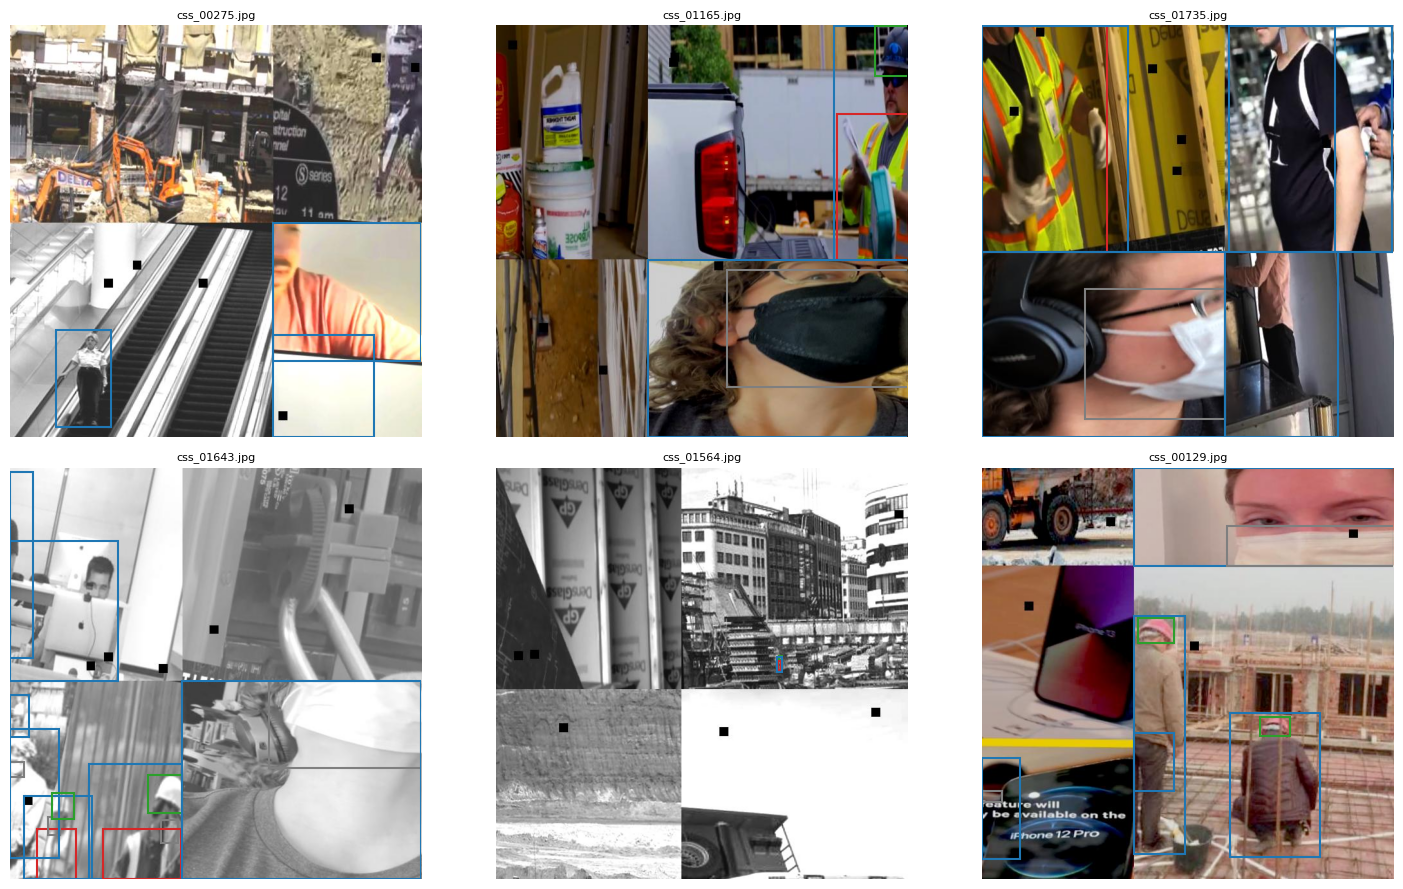

In [6]:
COLORS = {c: plt.cm.tab10(i) for i, c in enumerate(["person", "head", "helmet", "vest", "gloves", "boots", "goggles", "mask"])}
def show(ax, path, gt, title="", pred=None):
    ax.imshow(Image.open(path).convert("RGB")); ax.set_title(title, fontsize=8); ax.axis("off")
    for c, x1, y1, x2, y2 in gt:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, color=COLORS[c]))
    for c, s, x1, y1, x2, y2 in (pred or []):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.2, ls="--", color="red"))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, r in zip(axes.flat, random.Random(1).sample(split["train"], min(6, len(split["train"])))):
    show(ax, r["path"], r["boxes"], Path(r["path"]).name)
plt.tight_layout(); plt.savefig(RES / "samples.png", dpi=80); plt.show()

## 2 · Baseline: the pretrained models the app uses today

In [7]:
def box_iou(a, b):
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

_trapz = getattr(np, "trapezoid", None) or np.trapz
THRS = np.arange(0.5, 0.96, 0.05)

def average_precision(preds, gts, classes):
    # COCO-style AP per class at IoU 0.50:0.95 (101-point interpolation, like Ultralytics).
    # preds / gts: {image: [(class_name, [score,] x1, y1, x2, y2)]}
    ap = {}
    for c in classes:
        g = {img: np.array([x[1:] for x in gt if x[0] == c]).reshape(-1, 4) for img, gt in gts.items()}
        n_gt = sum(len(v) for v in g.values())
        if n_gt == 0:
            continue
        dets = sorted([(s, img, np.array(b)) for img, ps in preds.items() if img in g for (k, s, *b) in ps if k == c],
                      key=lambda d: -d[0])
        row = []
        for thr in THRS:
            used = {img: np.zeros(len(v), bool) for img, v in g.items()}
            tp = np.zeros(len(dets))
            for j, (s, img, b) in enumerate(dets):
                if len(g[img]):
                    ious = box_iou(b[None], g[img])[0]; ious[used[img]] = -1; m = ious.argmax()
                    if ious[m] >= thr:
                        tp[j], used[img][m] = 1, True
            tpc, fpc = np.cumsum(tp), np.cumsum(1 - tp)
            mrec = np.concatenate([[0], tpc / n_gt, [1]]); mpre = np.concatenate([[1], tpc / np.maximum(tpc + fpc, 1e-9), [0]])
            mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
            x = np.linspace(0, 1, 101)
            row.append(_trapz(np.interp(x, mrec, mpre), x))
        ap[c] = np.array(row)
    return ap

def summarize(name, ap):
    return {"model": name, "mAP50": np.mean([v[0] for v in ap.values()]), "mAP50-95": np.mean([v.mean() for v in ap.values()]),
            **{f"AP50 {c}": v[0] for c, v in ap.items()}}

def run_models(specs, paths, conf=0.001, batch=16):
    # specs: [(YOLO model, {model class -> app class} or None)]; several models are merged like the app does
    out = {}
    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        per = [[] for _ in chunk]
        for model, cmap in specs:
            for j, res in enumerate(model.predict(chunk, conf=conf, iou=0.6, imgsz=IMGSZ, device=DEVICE, verbose=False, max_det=300)):
                for b, s, k in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy(), res.boxes.cls.cpu().numpy().astype(int)):
                    name = model.names[int(k)]
                    c = name if cmap is None else cmap.get(name)
                    if c:
                        per[j].append((c, float(s), *map(float, b)))
        for p, dets in zip(chunk, per):
            if len(specs) > 1 and dets:
                ids = {c: i for i, c in enumerate(sorted({d[0] for d in dets}))}
                keep = torchvision.ops.batched_nms(torch.tensor([d[2:] for d in dets]), torch.tensor([d[1] for d in dets]),
                                                   torch.tensor([ids[d[0]] for d in dets]), 0.6).numpy()
                dets = [dets[k] for k in keep]
            out[p] = dets
    return out

def gts_of(rs):
    return {r.get("path", str(r["image"])): r["boxes"] for r in rs}

TEACHERS = {
    "SH17": ("https://github.com/ahmadmughees/SH17dataset/releases/download/v1/yolo8s.pt",
             {"person": "person", "head": "head", "helmet": "helmet", "safety-vest": "vest", "gloves": "gloves",
              "shoes": "boots", "glasses": "goggles", "face-mask": "mask"}),
    "site-safety": ("https://github.com/snehilsanyal/Construction-Site-Safety-PPE-Detection/raw/main/models/best.pt",
                    {"Hardhat": "helmet", "Safety Vest": "vest", "Mask": "mask", "Person": "person"}),
}
teachers = {t: (YOLO(str(download(u, RAW / f"teacher_{t}.pt"))), m) for t, (u, m) in TEACHERS.items()}
test_gt = gts_of(split["test"]); test_paths = list(test_gt)
rows = [summarize(f"pretrained: {t}", average_precision(run_models([spec], test_paths), test_gt, CLASSES)) for t, spec in teachers.items()]
rows.append(summarize("pretrained ensemble (current app)", average_precision(run_models(list(teachers.values()), test_paths), test_gt, CLASSES)))
baseline = pd.DataFrame(rows).set_index("model")
display(baseline.round(3))

downloading https://github.com/ahmadmughees/SH17dataset/releases/download/v1/yolo8s.pt
downloading https://github.com/snehilsanyal/Construction-Site-Safety-PPE-Detection/raw/main/models/best.pt


,mAP50,mAP50-95,AP50 person,AP50 helmet,AP50 vest,AP50 mask
model,,,,,,
pretrained: SH17,0.384,0.197,0.484,0.367,0.283,0.401
pretrained: site-safety,0.908,0.710,0.935,0.828,0.894,0.972
pretrained ensemble (current app),0.897,0.684,0.913,0.818,0.886,0.968


⚠️ The site-safety teacher was trained on the Construction Site Safety data, so its baseline on
notebook C's test set is flattered (it has probably seen those images).

## 3 · Fine-tune

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=css, nbs=64, nms=None, opset=None, optimize=False, optimizer

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      4.69G      1.351      1.608      1.455         44        640: 100% ━━━━━━━━━━━━ 123/123 5.5it/s 22.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.1it/s 3.5s
                   all        421       2738      0.457      0.375      0.331      0.173

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      4.69G        1.4      1.695      1.498         48        640: 100% ━━━━━━━━━━━━ 123/123 5.4it/s 22.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.9it/s 3.6s
                   all        421       2738      0.539      0.416      0.422      0.224

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      4.69G       1.38      1.651      1.484         76        640: 100% ━━━━━━━━━━━━ 123/123 5.3it/s 23.1s
                 Class     Images  Instances      Box

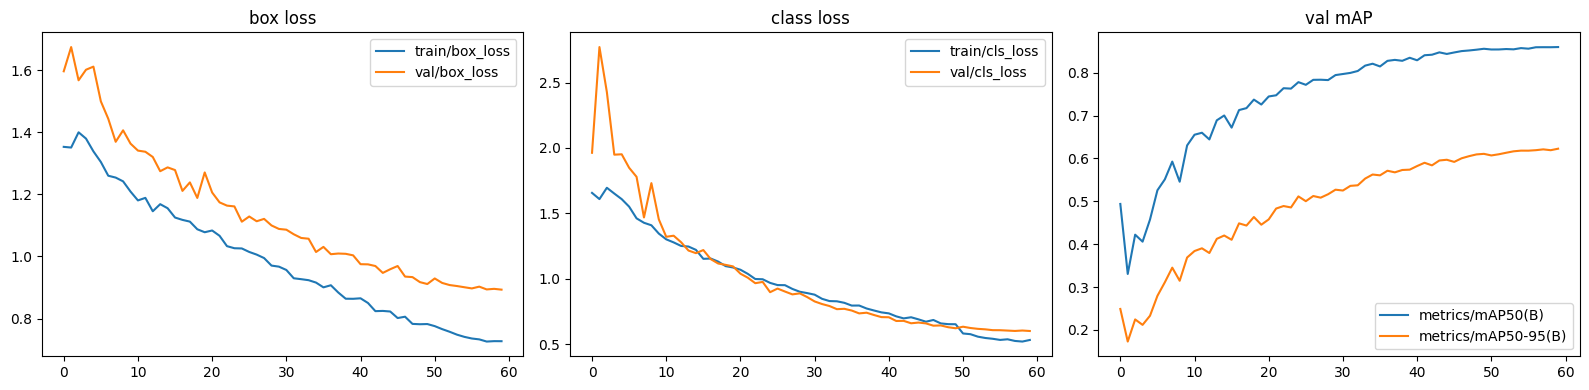

In [8]:
m = YOLO(MODEL)
t0 = time.time()
m.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED, project=str(WORK / "runs"), name=DATASET,
        exist_ok=True, patience=15, cos_lr=True, close_mosaic=10, device=DEVICE, workers=4 if ON_KAGGLE else 0, plots=True, verbose=False)
best_pt = Path(m.trainer.best)
print(f"trained in {(time.time() - t0) / 60:.1f} min ->", best_pt)

csv = pd.read_csv(best_pt.parent.parent / "results.csv"); csv.columns = [c.strip() for c in csv.columns]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
csv[["train/box_loss", "val/box_loss"]].plot(ax=ax[0], title="box loss")
csv[["train/cls_loss", "val/cls_loss"]].plot(ax=ax[1], title="class loss")
csv[["metrics/mAP50(B)", "metrics/mAP50-95(B)"]].plot(ax=ax[2], title="val mAP")
plt.tight_layout(); plt.savefig(RES / "training_curves.png", dpi=80); plt.show()

## 4 · Evaluate on this dataset's test set

,mAP50,mAP50-95,AP50 person,AP50 helmet,AP50 vest,AP50 mask
model,,,,,,
pretrained: SH17,0.384,0.197,0.484,0.367,0.283,0.401
pretrained: site-safety,0.908,0.710,0.935,0.828,0.894,0.972
pretrained ensemble (current app),0.897,0.684,0.913,0.818,0.886,0.968
fine-tuned yolo11s,0.881,0.638,0.895,0.821,0.858,0.948


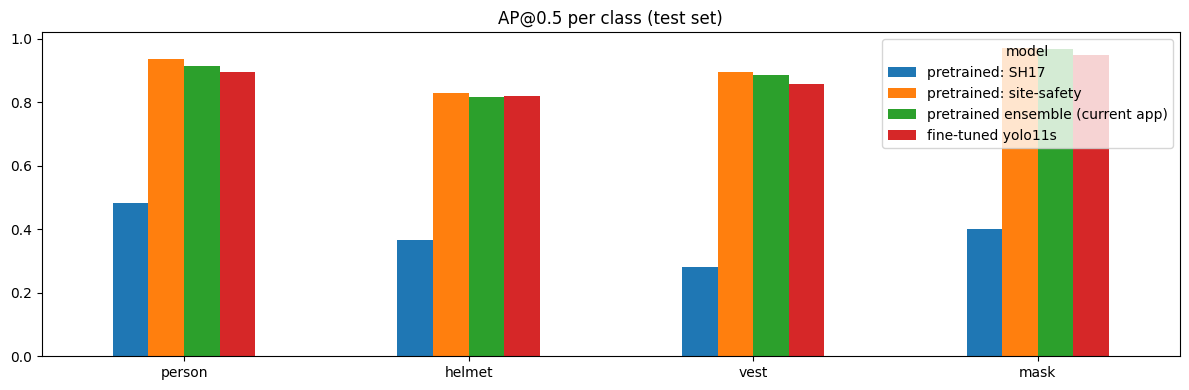

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1615.2±239.9 MB/s, size: 59.4 KB)
val: Scanning /kaggle/working/data/labels... 420 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 1.1Kit/s 0.4s
val: New cache created: /kaggle/working/data/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.7it/s 7.3s
                   all        420       2506      0.913      0.799       0.87      0.626
Speed: 1.5ms preprocess, 10.4ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /kaggle/working/runs/css_test
Ultralytics test mAP50 = 0.870 | mAP50-95 = 0.626


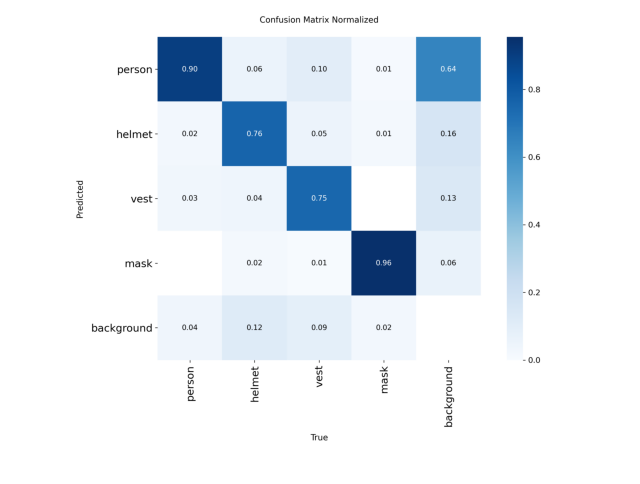

In [9]:
ft = YOLO(str(best_pt))
ft_preds = run_models([(ft, None)], test_paths)
ours = summarize(f"fine-tuned {Path(MODEL).stem}", average_precision(ft_preds, test_gt, CLASSES))
comparison = pd.concat([baseline, pd.DataFrame([ours]).set_index("model")])
display(comparison.round(3)); comparison.to_csv(RES / "comparison.csv")
ap_cols = [f"AP50 {c}" for c in CLASSES if f"AP50 {c}" in comparison]
ax = comparison[ap_cols].T.plot.bar(figsize=(12, 4), title="AP@0.5 per class (test set)")
ax.set_xticklabels([c.replace("AP50 ", "") for c in ap_cols], rotation=0); plt.tight_layout()
plt.savefig(RES / "ap_per_class.png", dpi=80); plt.show()

metrics = ft.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, device=DEVICE, project=str(WORK / "runs"), name=f"{DATASET}_test", exist_ok=True, verbose=False)
print(f"Ultralytics test mAP50 = {metrics.box.map50:.3f} | mAP50-95 = {metrics.box.map:.3f}")
cm = Path(metrics.save_dir) / "confusion_matrix_normalized.png"
if cm.exists():
    plt.figure(figsize=(8, 7)); plt.imshow(Image.open(cm)); plt.axis("off"); plt.show()

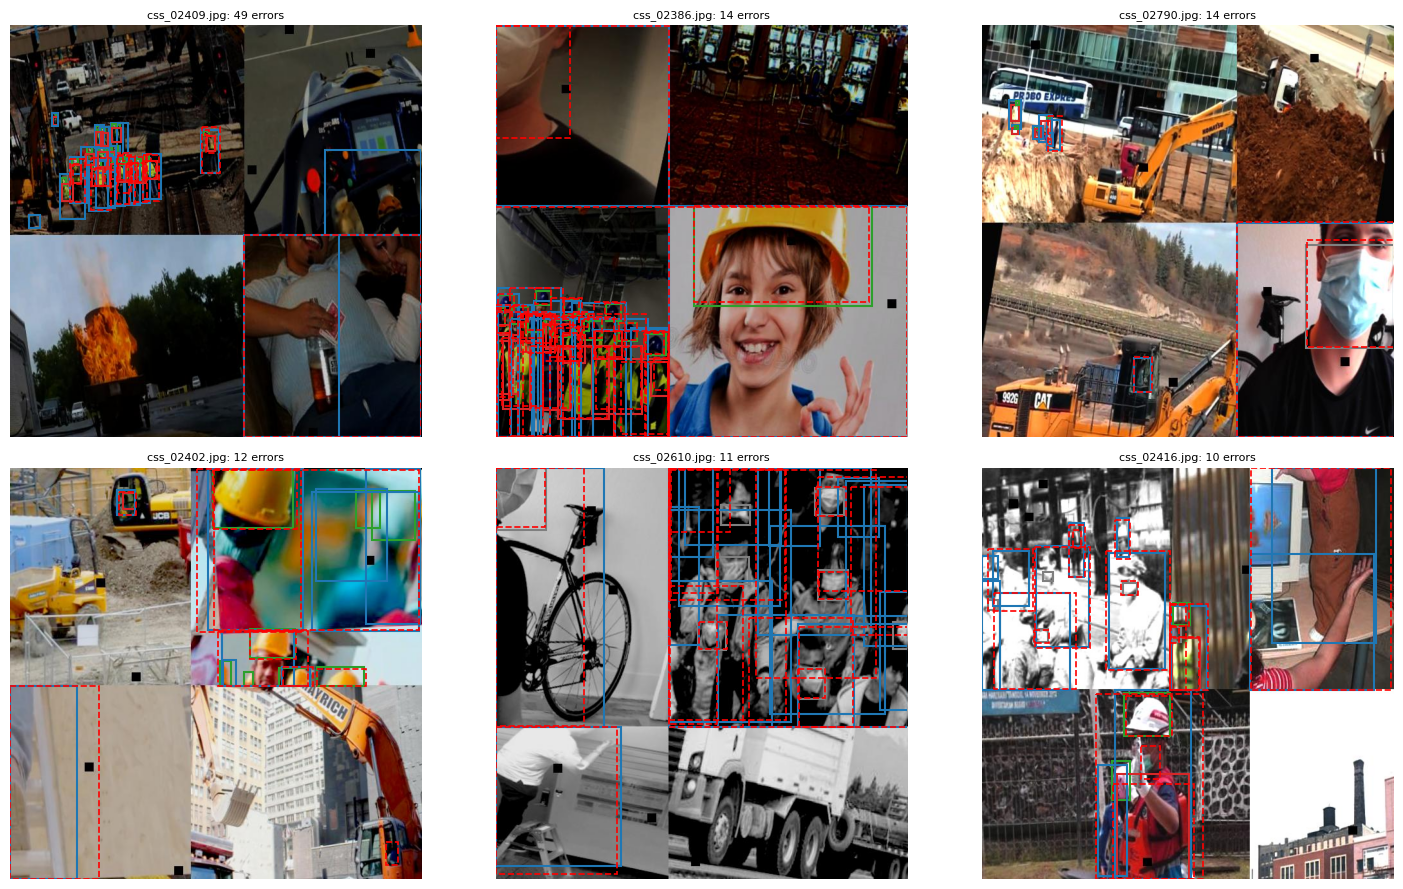

In [10]:
# failure gallery: most missed (solid = ground truth) or wrong (red dashed) boxes at conf 0.35
def n_errors(p):
    g = test_gt[p]; d = [x for x in ft_preds[p] if x[1] >= 0.35]; matched, fp = set(), 0
    for c, s, *b in d:
        ok = [i for i, (gc, *gb) in enumerate(g) if gc == c and i not in matched and box_iou(np.array([b]), np.array([gb]))[0, 0] >= 0.5]
        if ok: matched.add(ok[0])
        else: fp += 1
    return len(g) - len(matched) + fp, d
worst = sorted(test_paths, key=lambda p: -n_errors(p)[0])[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axes.flat, worst):
    k, d = n_errors(p); show(ax, p, test_gt[p], f"{Path(p).name}: {k} errors", pred=d)
plt.tight_layout(); plt.savefig(RES / "failures.png", dpi=80); plt.show()

## 5 · Cross-dataset test

The same model on the **other two datasets** (that it never saw), scored only on the classes both
datasets label. A big drop compared with section 4 means the model learned the look of *its*
dataset rather than PPE in general. The pretrained ensemble is shown for comparison.

In [11]:
cross = []
for other, loader in LOADERS.items():
    if other == DATASET:
        continue
    recs, other_labeled = loader()
    shared = [c for c in CLASSES if c in other_labeled]
    if not recs or not shared:
        print(f"{TITLES[other]}: skipped ({'not attached' if not recs else 'no shared classes'})"); continue
    recs = random.Random(SEED).sample(recs, min(CROSS_TEST_MAX, len(recs)))
    gt = {str(r["image"]): [b for b in r["boxes"] if b[0] in shared] for r in recs}
    for name, specs in (("fine-tuned (this notebook)", [(ft, None)]), ("pretrained ensemble", list(teachers.values()))):
        ap = average_precision(run_models(specs, list(gt)), gt, shared)
        cross.append({"tested on": TITLES[other], "model": name, "classes": ", ".join(shared), "images": len(gt),
                      "mAP50": np.mean([v[0] for v in ap.values()]), "mAP50-95": np.mean([v.mean() for v in ap.values()])})
cross.insert(0, {"tested on": TITLES[DATASET] + " (own test set)", "model": "fine-tuned (this notebook)", "classes": ", ".join(CLASSES),
                 "images": len(test_gt), "mAP50": ours["mAP50"], "mAP50-95": ours["mAP50-95"]})
cross = pd.DataFrame(cross)
display(cross.round(3)); cross.to_csv(RES / "cross_dataset.csv", index=False)

downloading https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip
Hard Hat Workers: skipped (not attached)


,tested on,model,classes,images,mAP50,mAP50-95
0,Construction Site Safety (own test set),fine-tuned (this notebook),"person, helmet, vest, mask",420,0.881,0.638
1,Construction-PPE,fine-tuned (this notebook),"person, helmet, vest",600,0.610,0.236
2,Construction-PPE,pretrained ensemble,"person, helmet, vest",600,0.733,0.312


## 6 · Export to ONNX (what the app runs) + per-worker check

In [12]:
FINAL = WORK / f"safesight_{DATASET}_{Path(MODEL).stem}.onnx"
shutil.copy(ft.export(format="onnx", imgsz=IMGSZ, opset=17, simplify=True, dynamic=False), FINAL)
size_mb = FINAL.stat().st_size / 1e6
print(f"{FINAL.name}: {size_mb:.1f} MB", "OK for the app (<= 50 MB)" if size_mb <= 50 else "TOO BIG: use a smaller model or half=True")

chk = test_paths[:20]
a = run_models([(ft, None)], chk, conf=0.35); b = run_models([(YOLO(str(FINAL), task="detect"), None)], chk, conf=0.35)
hits = sum(any(c2 == c and box_iou(np.array([bx]), np.array([bx2]))[0, 0] >= 0.85 for c2, s2, *bx2 in b[p]) for p in chk for c, s, *bx in a[p])
print(f"ONNX reproduces {hits}/{sum(len(a[p]) for p in chk)} PyTorch detections")

import onnxruntime as ort
sess = ort.InferenceSession(str(FINAL), providers=["CPUExecutionProvider"])
x = np.random.rand(1, 3, IMGSZ, IMGSZ).astype(np.float32); inp = sess.get_inputs()[0].name
sess.run(None, {inp: x}); t0 = time.time()
for _ in range(10):
    sess.run(None, {inp: x})
cpu_ms = (time.time() - t0) / 10 * 1000
print(f"CPU inference: {cpu_ms:.0f} ms / image")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/css/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (18.3 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.3s, saved as '/kaggle/working/runs/css/weights/best.onnx' (36.2 MB)

Export complete (2.8s)
Results saved to /kaggle/working/runs/css/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/css/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/runs/css/weights/best.onnx imgsz=640 data=/kaggle/working/data/data.yaml 
Visualize:       https://netron.app

In [13]:
# Per-worker helmet / vest accuracy with the app's own pipeline (pose model + this detector).
# Needs labelled persons (not available for Hard Hat Workers) and the ppe_core folder.
core = next(iter(sorted(INPUT.glob("**/ppe_core/__init__.py"))), None) if INPUT.exists() else None
if core is None and (Path.cwd().parent / "backend" / "ppe_core").exists():
    core = Path.cwd().parent / "backend" / "ppe_core" / "__init__.py"
ITEMS = [c for c in ("helmet", "vest") if c in CLASSES]
workers = None
if "person" not in CLASSES or not ITEMS:
    print("skipped: this dataset has no labelled persons")
elif core is None:
    print("skipped: add backend/ppe_core as a Kaggle dataset to run this check")
else:
    sys.path.insert(0, str(core.parent.parent))
    from ppe_core.config import AppConfig, AssociationConfig, DetectorConfig, PoseConfig
    from ppe_core.pipeline import Pipeline
    def to_onnx(pt, name):
        out = RAW / f"{name}.onnx"
        if not out.exists():
            shutil.copy(YOLO(str(pt)).export(format="onnx", imgsz=640, opset=17, simplify=True), out)
        return out
    pose_onnx = to_onnx("yolo11n-pose.pt", "yolo11n-pose")
    pipe = Pipeline(AppConfig(detectors=[DetectorConfig(name="ours", weights=str(FINAL))], pose=PoseConfig(weights=str(pose_onnx)),
                              association=AssociationConfig(), default_required=ITEMS))
    def iou1(a, b):
        return box_iou(np.array([a]), np.array([b]))[0, 0]
    def truth(person, gt, item):
        x1, y1, x2, y2 = person; h = y2 - y1
        reg = (x1, y1 - 0.05 * h, x2, y1 + 0.25 * h) if item == "helmet" else (x1, y1 + 0.15 * h, x2, y1 + 0.65 * h)
        for c, *b in gt:
            if c == item:
                inter = max(0, min(b[2], reg[2]) - max(b[0], reg[0])) * max(0, min(b[3], reg[3]) - max(b[1], reg[1]))
                if inter / max((b[2] - b[0]) * (b[3] - b[1]), 1e-9) >= 0.4:
                    return "worn"
        return "absent"
    stat = {i: dict(agree=0, decided=0, unknown=0, tp=0, fp=0, fn=0) for i in ITEMS}; found = total = 0
    for p, gt in test_gt.items():
        persons = [b for c, *b in gt if c == "person" and b[3] - b[1] >= 48]
        if not persons:
            continue
        out = pipe.run(np.asarray(Image.open(p).convert("RGB")), ITEMS); used = set()
        for per in persons:
            total += 1
            best = max(((iou1(per, (q.person.box.x1, q.person.box.y1, q.person.box.x2, q.person.box.y2)), j)
                        for j, q in enumerate(out.assessments) if j not in used), default=(0, -1))
            if best[0] < 0.5:
                continue
            used.add(best[1]); found += 1
            for item in ITEMS:
                s, t, m = out.assessments[best[1]].items[item].state, truth(per, gt, item), stat[item]
                if s == "unknown":
                    m["unknown"] += 1; continue
                m["decided"] += 1; m["agree"] += (s == "worn") == (t == "worn")
                m["tp"] += s == "absent" and t == "absent"; m["fp"] += s == "absent" and t == "worn"; m["fn"] += s == "worn" and t == "absent"
    workers = pd.DataFrame({i: {"workers found": found / max(total, 1), "accuracy": m["agree"] / max(m["decided"], 1),
                                "violation precision": m["tp"] / max(m["tp"] + m["fp"], 1), "violation recall": m["tp"] / max(m["tp"] + m["fn"], 1),
                                "unknown rate": m["unknown"] / max(m["decided"] + m["unknown"], 1)} for i, m in stat.items()}).T
    display(workers.round(3)); workers.to_csv(RES / "per_worker.csv")

skipped: add backend/ppe_core as a Kaggle dataset to run this check


In [14]:
summary = {"dataset": TITLES[DATASET], "classes": CLASSES, "base_model": MODEL, "epochs": EPOCHS,
           "images": {k: len(v) for k, v in split.items()}, "test_mAP50": round(float(ours["mAP50"]), 4),
           "test_mAP50_95": round(float(ours["mAP50-95"]), 4),
           "baseline_mAP50": round(float(baseline.loc["pretrained ensemble (current app)", "mAP50"]), 4),
           "onnx_file": FINAL.name, "onnx_mb": round(size_mb, 1), "cpu_ms": round(cpu_ms)}
(RES / "summary.json").write_text(json.dumps(summary, indent=2)); print(json.dumps(summary, indent=2))
print(f"\nNext: download {FINAL.name} + results/ from Output -> app -> Models -> Register -> Add to ensemble")

{
  "dataset": "Construction Site Safety",
  "classes": [
    "person",
    "helmet",
    "vest",
    "mask"
  ],
  "base_model": "yolo11s.pt",
  "epochs": 60,
  "images": {
    "train": 1959,
    "val": 421,
    "test": 420
  },
  "test_mAP50": 0.8805,
  "test_mAP50_95": 0.6383,
  "baseline_mAP50": 0.8966,
  "onnx_file": "safesight_css_yolo11s.onnx",
  "onnx_mb": 37.9,
  "cpu_ms": 147
}

Next: download safesight_css_yolo11s.onnx + results/ from Output -> app -> Models -> Register -> Add to ensemble
